In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns




In [3]:
file_path = r"C:\Users\janfr\OneDrive - Delft University of Technology\Bestanden van Chris van Bodegom - TIL6022 Groep 14\traindata_filtered_2024.csv"

# Load the dataset
datas = pd.read_csv(file_path, low_memory=False)

# Preview the first 5 rows to confirm it loaded
datas.head()

,Service:RDT-ID,Service:Date,Service:Type,Service:Company,Service:Train number,Service:Completely cancelled,Service:Partly cancelled,Service:Maximum delay,Stop:RDT-ID,Stop:Station code,Stop:Station name,Stop:Arrival time,Stop:Arrival delay,Stop:Arrival cancelled,Stop:Departure time,Stop:Departure delay,Stop:Departure cancelled,Stop:Platform change,Stop:Planned platform,Stop:Actual platform
0,12719194,2024-01-06,Intercity,NS,22401,False,False,0,114586491,UT,Utrecht Centraal,NaN,NaN,NaN,2024-01-06T02:00:00+01:00,0.0,False,False,9,9
1,12719194,2024-01-06,Intercity,NS,22401,False,False,0,114586492,AMF,Amersfoort Centraal,2024-01-06T02:14:00+01:00,0.0,False,NaN,NaN,NaN,False,2,2
2,12719195,2024-01-06,Intercity,NS,22201,False,False,1,114586493,HLM,Haarlem,NaN,NaN,NaN,2024-01-06T02:00:00+01:00,0.0,False,False,1,1
3,12719195,2024-01-06,Intercity,NS,22201,False,False,0,114586494,ASD,Amsterdam Centraal,2024-01-06T02:13:00+01:00,1.0,False,NaN,NaN,NaN,False,7a,7a
4,12719196,2024-01-06,Intercity,NS,1410,False,False,0,114586495,RTD,Rotterdam Centraal,NaN,NaN,NaN,2024-01-06T02:00:00+01:00,0.0,False,False,7,7


In [4]:
target_stations = [
    # Amsterdam
    "Amsterdam Bijlmer ArenA", "Amsterdam Centraal", "Amsterdam Holendrecht", 
    "Amsterdam Lelylaan", "Amsterdam Muiderpoort", "Amsterdam RAI", 
    "Amsterdam Science Park", "Amsterdam Sloterdijk", "Amsterdam Zuid",
    # Rotterdam
    "Rotterdam Alexander", "Rotterdam Blaak", "Rotterdam Centraal", 
    "Rotterdam Lombardijen", "Rotterdam Noord", "Rotterdam Zuid",
    # Den Haag
    "Den Haag Centraal", "Den Haag HS", "Den Haag Laan v NOI", 
    "Den Haag Mariahoeve", "Den Haag Moerwijk", "Den Haag Ypenburg",
    # Additions
    "Utrecht Centraal", "Eindhoven Centraal", "Emmen", "Emmen Zuid"
]

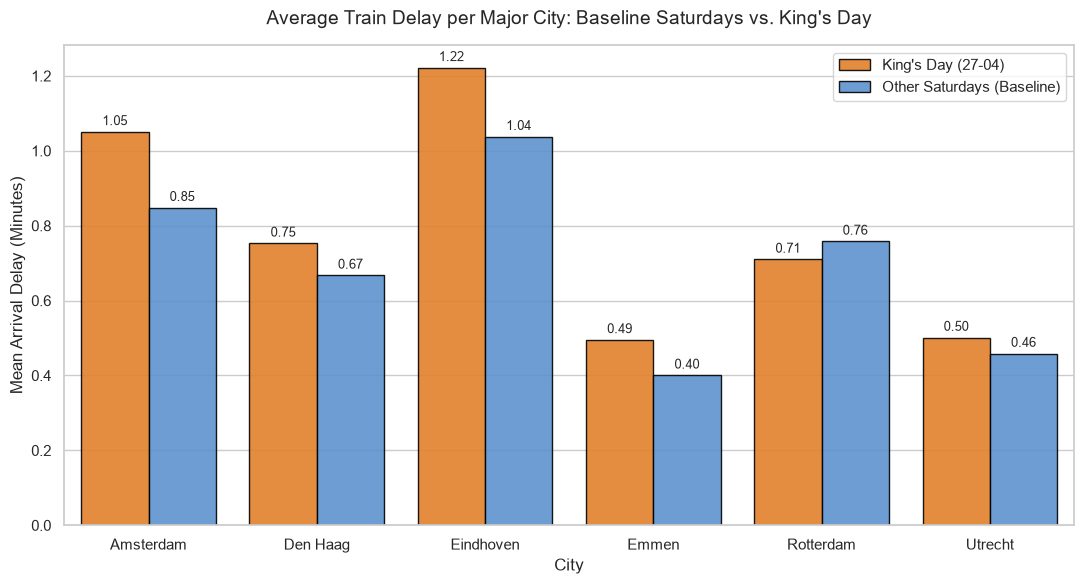

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



# 2. Filter dataset for selected stations
df_filtered = datas[datas['Stop:Station name'].isin(target_stations)].copy()

# 3. Clean numeric delay column
df_filtered['Stop:Arrival delay'] = pd.to_numeric(
    df_filtered['Stop:Arrival delay'], errors='coerce'
).fillna(0.0)

# 4. Map stations to their parent cities
def get_parent_city(station_name):
    if station_name.startswith("Amsterdam"): return "Amsterdam"
    if station_name.startswith("Rotterdam"): return "Rotterdam"
    if station_name.startswith("Den Haag"): return "Den Haag"
    if station_name.startswith("Utrecht"): return "Utrecht"
    if station_name.startswith("Eindhoven"): return "Eindhoven"
    if station_name.startswith("Emmen"): return "Emmen"
    return "Other"

df_filtered['City'] = df_filtered['Stop:Station name'].apply(get_parent_city)

# 5. Classify dates: King's Day vs. All other Saturdays in the dataset
df_filtered['Day Type'] = np.where(
    df_filtered['Service:Date'] == '2024-04-27', 
    "King's Day (27-04)", 
    "Other Saturdays (Baseline)"
)

# 6. Calculate the aggregated average delay per city and day type
city_comparison = (
    df_filtered.groupby(['City', 'Day Type'])['Stop:Arrival delay']
    .mean()
    .reset_index()
)

# 7. Plot the grouped bar chart
plt.figure(figsize=(11, 6))
sns.set_theme(style="whitegrid")

# Define color contrast
palette = {
    'Other Saturdays (Baseline)': '#4A90E2',  # Neutral blue for average baseline
    "King's Day (27-04)": '#FF7F0E'           # Orange for the holiday
}

ax = sns.barplot(
    data=city_comparison,
    x='City',
    y='Stop:Arrival delay',
    hue='Day Type',
    palette=palette,
    edgecolor='black',
    alpha=0.9
)

# 8. Add direct value labels on top of bars for exact readability
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{height:.2f}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=9, xytext=(0, 3),
            textcoords='offset points'
        )

# Titles and formatting
plt.title("Average Train Delay per Major City: Baseline Saturdays vs. King's Day", fontsize=14, pad=15)
plt.xlabel("City", fontsize=12)
plt.ylabel("Mean Arrival Delay (Minutes)", fontsize=12)
plt.legend(title="", frameon=True)
plt.tight_layout()

# Display the chart
plt.show()

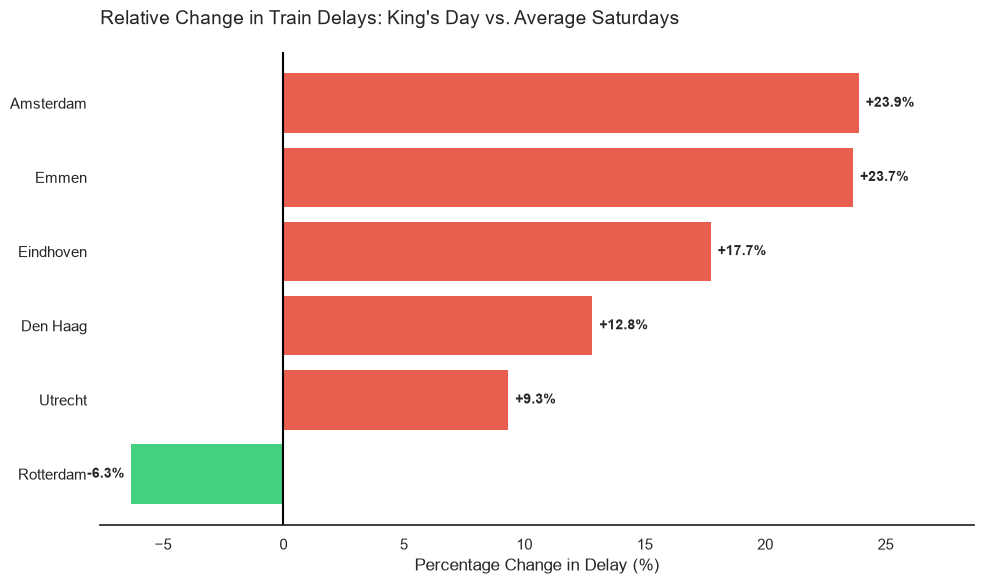

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# 2. Filter dataset and map to parent cities
df_filtered = datas[datas['Stop:Station name'].isin(target_stations)].copy()
df_filtered['Stop:Arrival delay'] = pd.to_numeric(df_filtered['Stop:Arrival delay'], errors='coerce').fillna(0.0)

def get_parent_city(station_name):
    if station_name.startswith("Amsterdam"): return "Amsterdam"
    if station_name.startswith("Rotterdam"): return "Rotterdam"
    if station_name.startswith("Den Haag"): return "Den Haag"
    if station_name.startswith("Utrecht"): return "Utrecht"
    if station_name.startswith("Eindhoven"): return "Eindhoven"
    if station_name.startswith("Emmen"): return "Emmen"
    return "Other"

df_filtered['City'] = df_filtered['Stop:Station name'].apply(get_parent_city)

# 3. Classify dates: King's Day vs. Baseline (Other Saturdays)
df_filtered['Day Type'] = np.where(
    df_filtered['Service:Date'] == '2024-04-27', 
    "King's Day", 
    "Baseline"
)

# 4. Calculate average delay and pivot the data
city_delays = df_filtered.groupby(['City', 'Day Type'])['Stop:Arrival delay'].mean().unstack()

# 5. Calculate the Percentage Change and Sort
city_delays['% Change'] = ((city_delays["King's Day"] - city_delays["Baseline"]) / city_delays["Baseline"]) * 100
plot_data = city_delays.reset_index()

# Sort the values from largest decrease to largest increase for a clean ranking
plot_data = plot_data.sort_values(by='% Change', ascending=True)

# 6. Define conditional colors (Red for > 0, Green for <= 0)
colors = ['#E74C3C' if val > 0 else '#2ECC71' for val in plot_data['% Change']]

# 7. Plotting the Sleek Horizontal Chart
plt.figure(figsize=(10, 6))
sns.set_theme(style="white") # Completely clean background without gridlines

# Horizontal bar chart
bars = plt.barh(plot_data['City'], plot_data['% Change'], color=colors, edgecolor='none', alpha=0.9)

# Add a distinct solid vertical baseline at 0%
plt.axvline(0, color='black', linewidth=1.5)

# 8. Add percentage labels directly next to the horizontal bars
for bar in bars:
    xval = bar.get_width()
    yval = bar.get_y() + bar.get_height() / 2
    
    # Position text to the right if positive, to the left if negative
    offset = 5 if xval > 0 else -5
    ha = 'left' if xval > 0 else 'right'
    
    plt.annotate(
        f'{xval:+.1f}%', 
        (xval, yval),
        ha=ha, va='center',
        fontsize=10, fontweight='bold',
        xytext=(offset, 0), textcoords='offset points'
    )

# Formatting
plt.title("Relative Change in Train Delays: King's Day vs. Average Saturdays", fontsize=14, pad=20, loc='left')
plt.xlabel("Percentage Change in Delay (%)", fontsize=12)
plt.ylabel("") # Remove the 'City' Y-axis label to eliminate clutter

# Remove outer borders (spines) for a modern, dashboard-ready design
sns.despine(left=True, bottom=False)

# Ensure the X-axis expands enough to fit the labels
plt.xlim(plot_data['% Change'].min() * 1.2, plot_data['% Change'].max() * 1.2)

plt.tight_layout()
plt.show()